## Conclusion

Ce notebook a évalué l'effet de la stratégie d'augmentation
sélectionnée précédemment, SMOTE avec un ratio Fraude/Normal
de 0.10, sur les cinq classifieurs étudiés.

Les modèles ont été entraînés sur le Train augmenté puis
évalués sur le jeu de Test réel et non rééchantillonné.

Les résultats ont été comparés à la baseline obtenue sur le
Train original déséquilibré afin de quantifier précisément
l'impact de l'augmentation sur la Precision, le Recall,
le F1-score, la ROC-AUC, l'Average Precision et la matrice
de confusion.

À ce stade, aucun classifieur n'est sélectionné définitivement.

Les cinq modèles sont conservés pour l'étude de robustesse
adversariale qui sera réalisée dans le notebook suivant à
l'aide de l'attaque ZOO.

In [32]:
for name in model_file_names.values():

    path = (
        MODELS_DIR /
        f"{name}.joblib"
    )

    print(
        path.name,
        "→",
        path.exists()
    )

logistic_regression.joblib → True
linear_svm.joblib → True
random_forest.joblib → True
xgboost.joblib → True
lightgbm.joblib → True


In [31]:
files_to_check = [

    METRICS_DIR /
    "augmented_test_metrics.csv",

    METRICS_DIR /
    "augmented_test_predictions.parquet",

    METRICS_DIR /
    "baseline_test_recomputed_09.csv",

    METRICS_DIR /
    "baseline_vs_augmented_test.csv",

    METRICS_DIR /
    "augmented_experiment_metadata.json",

    FIGURES_DIR /
    "augmented_precision_recall_curves.png"
]

for file in files_to_check:

    print(
        file.name,
        "→",
        file.exists()
    )

augmented_test_metrics.csv → True
augmented_test_predictions.parquet → True
baseline_test_recomputed_09.csv → True
baseline_vs_augmented_test.csv → True
augmented_experiment_metadata.json → True
augmented_precision_recall_curves.png → True


In [30]:
experiment_metadata = {

    "notebook":
        "09_augmented_models",

    "augmentation_method":
        BEST_METHOD,

    "fraud_normal_ratio":
        BEST_RATIO,

    "synthetic_samples_added":
        int(n_added),

    "real_train_samples":
        int(len(X_train)),

    "augmented_train_samples":
        int(len(X_train_aug)),

    "test_samples":
        int(len(X_test)),

    "test_frauds":
        int(
            (y_test == 1).sum()
        ),

    "test_normals":
        int(
            (y_test == 0).sum()
        ),

    "random_state":
        SEED,

    "selection_frozen_before_test":
        True,

    "final_model_selected":
        False
}

with open(
    METRICS_DIR /
    "augmented_experiment_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

print(
    "Métadonnées sauvegardées."
)

Métadonnées sauvegardées.


## Étape 21 — Positionnement des résultats

Les performances mesurées dans ce notebook décrivent
l'efficacité des cinq classifieurs sur des transactions
réelles après augmentation du Train.

Ces résultats permettent d'identifier les modèles les plus
performants en conditions normales, mais ils ne suffisent
pas à sélectionner le modèle final du système.

La solution recherchée doit être à la fois :

1. efficace sur les transactions propres ;
2. robuste face aux attaques adversariales.

Les cinq modèles sont donc conservés pour l'étape suivante,
consacrée à l'attaque ZOO en boîte noire.

La sélection finale interviendra uniquement après l'étude
de robustesse et l'Adversarial Training.

In [29]:
error_table = augmented_test_df[
    [
        "Modèle",
        "TN",
        "FP",
        "FN",
        "TP",
        "Precision",
        "Recall",
        "F1",
        "AP"
    ]
].copy()

display(
    error_table.round(4)
)

,Modèle,TN,FP,FN,TP,Precision,Recall,F1,AP
0,Régression logistique,42422,66,12,59,0.4720,0.8310,0.6020,0.6928
1,SVM linéaire,42453,35,14,57,0.6196,0.8028,0.6994,0.7058
2,Random Forest,42482,6,16,55,0.9016,0.7746,0.8333,0.8284
3,XGBoost,42476,12,16,55,0.8209,0.7746,0.7971,0.8004
4,LightGBM,42480,8,17,54,0.8710,0.7606,0.8120,0.7911


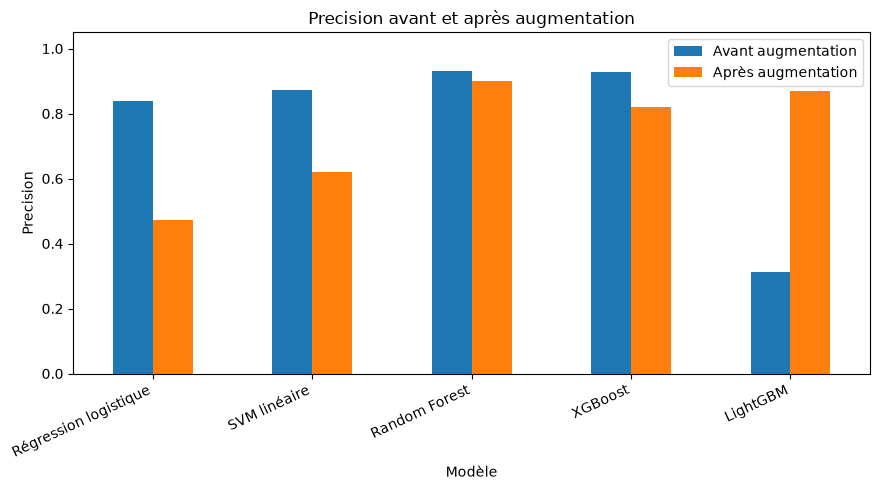

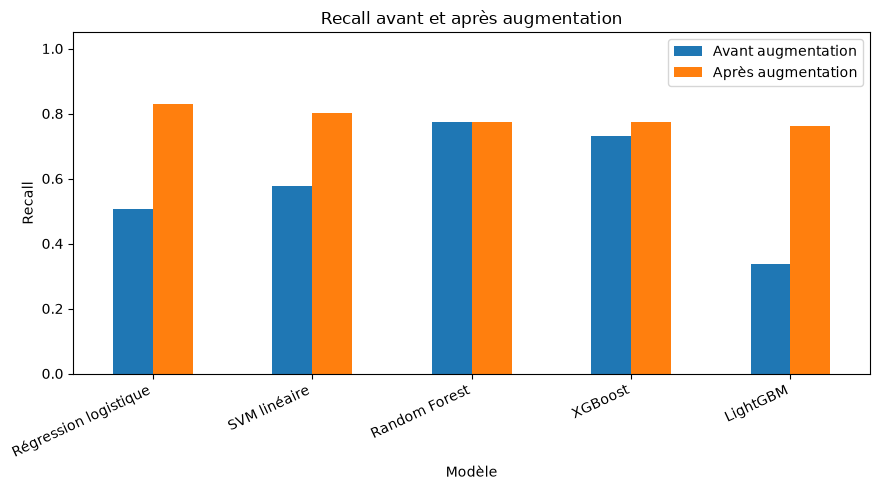

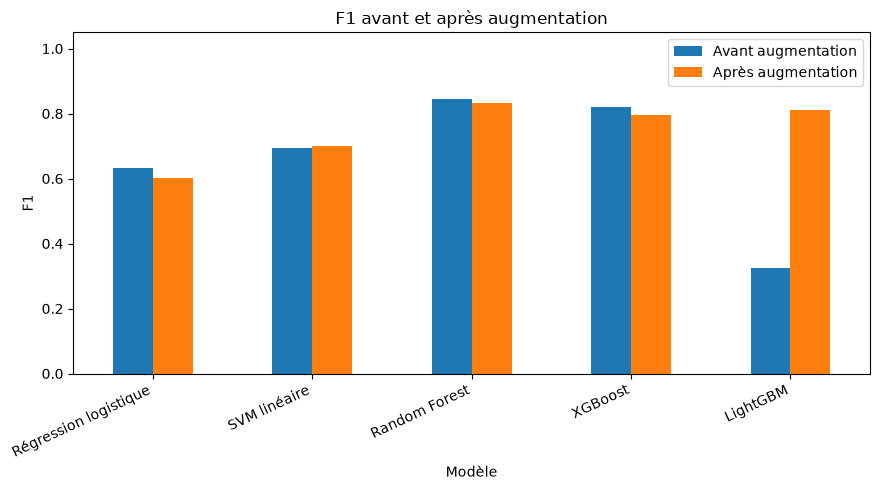

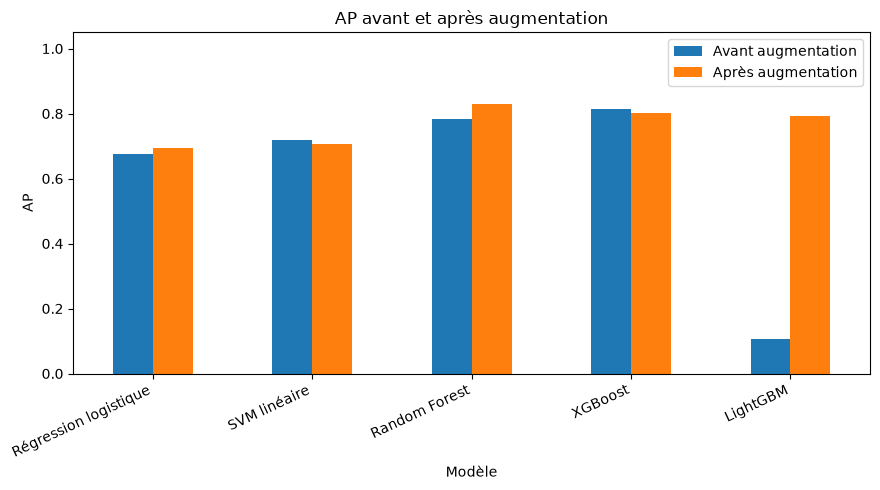

In [28]:
for metric in [
    "Precision",
    "Recall",
    "F1",
    "AP"
]:

    plot_df = comparison_df[
        [
            "Modèle",
            f"{metric}_Avant",
            f"{metric}_Après"
        ]
    ].copy()

    plot_df = (
        plot_df
        .set_index("Modèle")
    )

    plot_df.columns = [
        "Avant augmentation",
        "Après augmentation"
    ]

    ax = plot_df.plot(
        kind="bar",
        figsize=(9, 5)
    )

    ax.set_ylabel(
        metric
    )

    ax.set_title(
        f"{metric} avant et après augmentation"
    )

    ax.set_ylim(
        0,
        1.05
    )

    plt.xticks(
        rotation=25,
        ha="right"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR /
        f"before_after_{metric.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

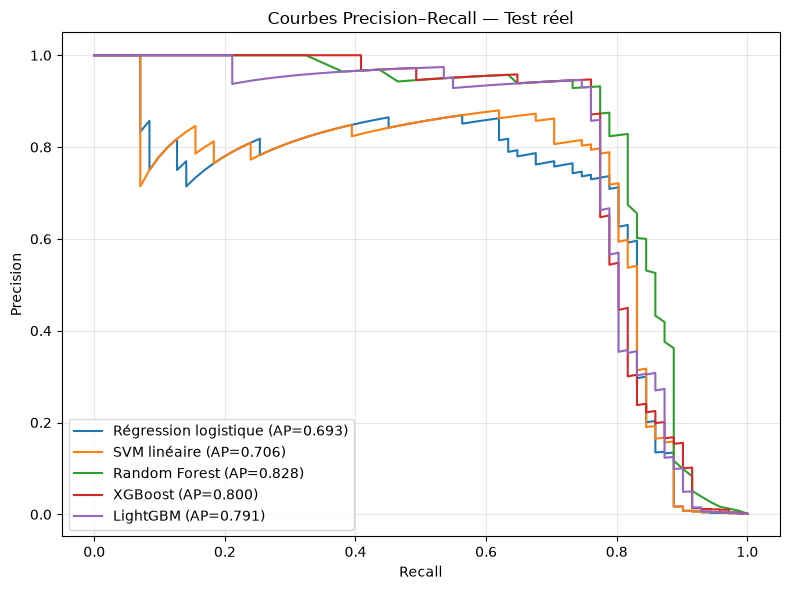

In [27]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

for model_name in model_file_names.keys():

    y_score = test_predictions[
        f"{model_name}_score"
    ]

    precision, recall, _ = (
        precision_recall_curve(
            y_test,
            y_score
        )
    )

    ap = float(
        augmented_test_df.loc[
            augmented_test_df[
                "Modèle"
            ] == model_name,
            "AP"
        ].iloc[0]
    )

    ax.plot(
        recall,
        precision,
        label=(
            f"{model_name} "
            f"(AP={ap:.3f})"
        )
    )

ax.set_xlabel(
    "Recall"
)

ax.set_ylabel(
    "Precision"
)

ax.set_title(
    "Courbes Precision–Recall — Test réel"
)

ax.legend()

ax.grid(
    alpha=0.3
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "augmented_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

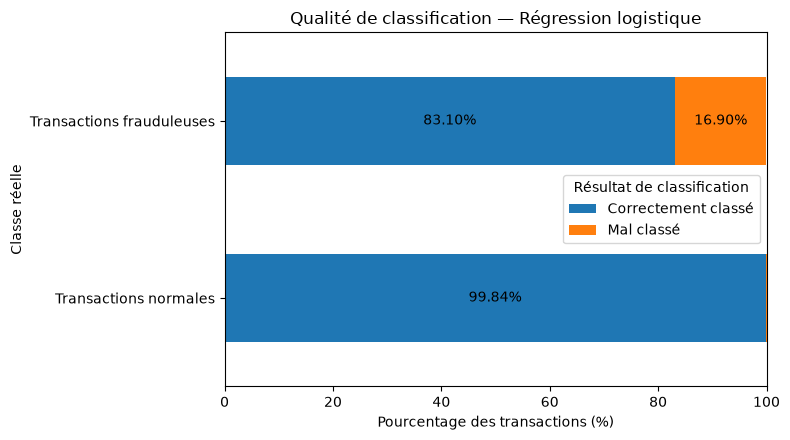

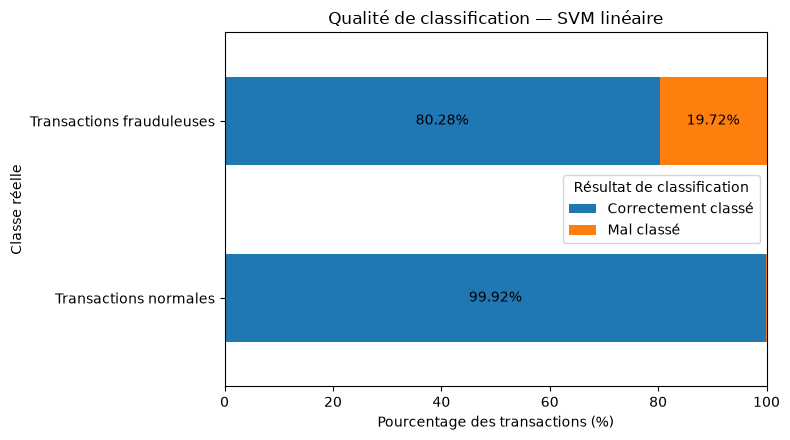

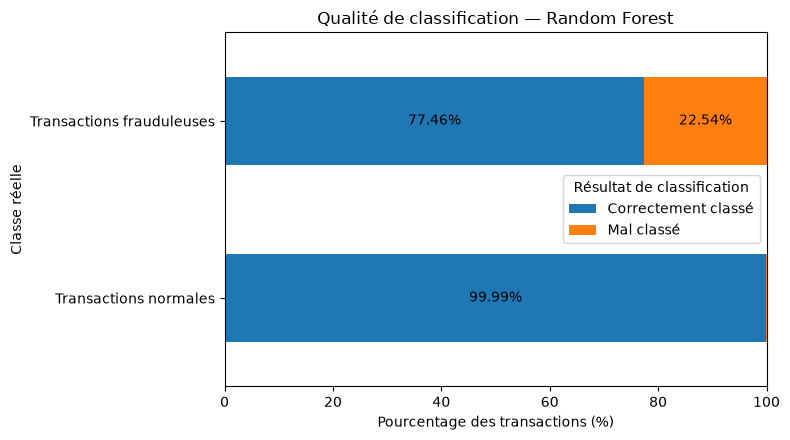

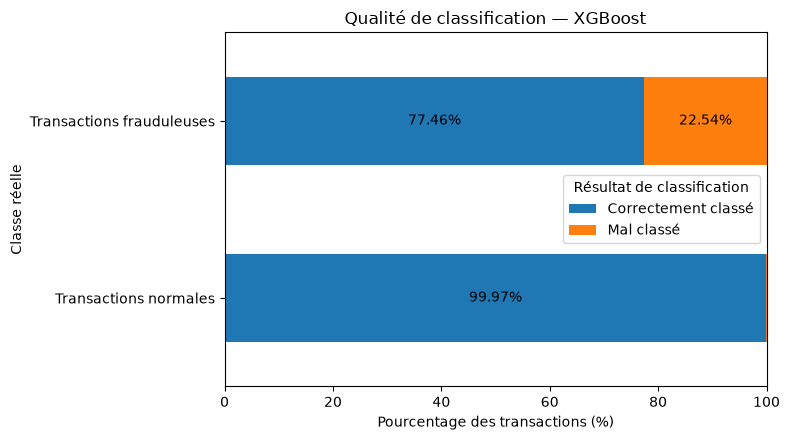

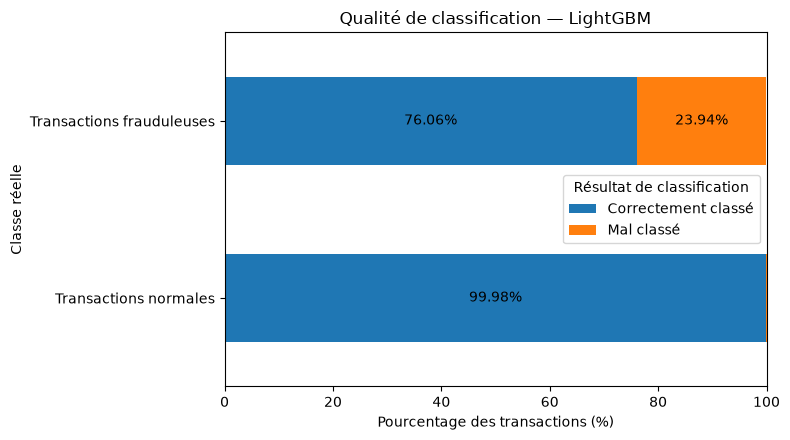

In [26]:
for model_name in model_file_names.keys():

    y_pred = test_predictions[
        f"{model_name}_pred"
    ]

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    # Normalisation par vraie classe
    cm_pct = (
        cm
        / cm.sum(axis=1, keepdims=True)
        * 100
    )

    plot_df = pd.DataFrame(
        {
            "Correctement classé": [
                cm_pct[0, 0],  # Normal prédit Normal
                cm_pct[1, 1]   # Fraude prédite Fraude
            ],
            "Mal classé": [
                cm_pct[0, 1],  # Normal prédit Fraude
                cm_pct[1, 0]   # Fraude prédite Normal
            ]
        },
        index=[
            "Transactions normales",
            "Transactions frauduleuses"
        ]
    )

    ax = plot_df.plot(
        kind="barh",
        stacked=True,
        figsize=(8, 4.5)
    )

    ax.set_xlim(
        0,
        100
    )

    ax.set_xlabel(
        "Pourcentage des transactions (%)"
    )

    ax.set_ylabel(
        "Classe réelle"
    )

    ax.set_title(
        f"Qualité de classification — {model_name}"
    )

    ax.legend(
        title="Résultat de classification"
    )

    # Ajouter les pourcentages sur les barres
    for container in ax.containers:

        labels = [
            f"{value:.2f}%"
            if value > 2
            else ""
            for value in container.datavalues
        ]

        ax.bar_label(
            container,
            labels=labels,
            label_type="center"
        )

    plt.tight_layout()

    filename = (
        model_file_names[
            model_name
        ]
        +
        "_classification_stacked.png"
    )

    plt.savefig(
        FIGURES_DIR /
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

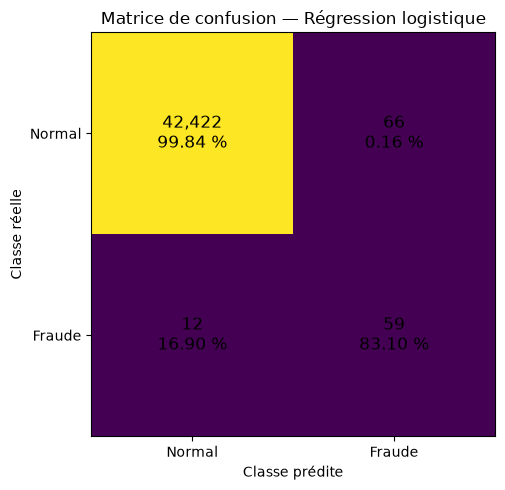

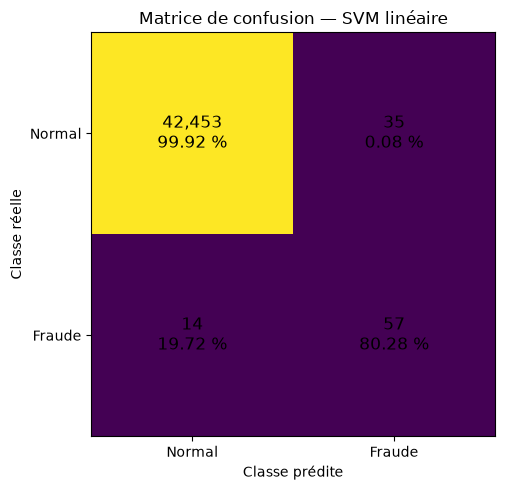

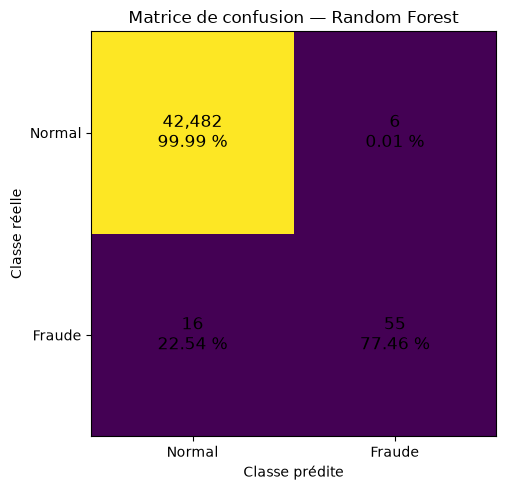

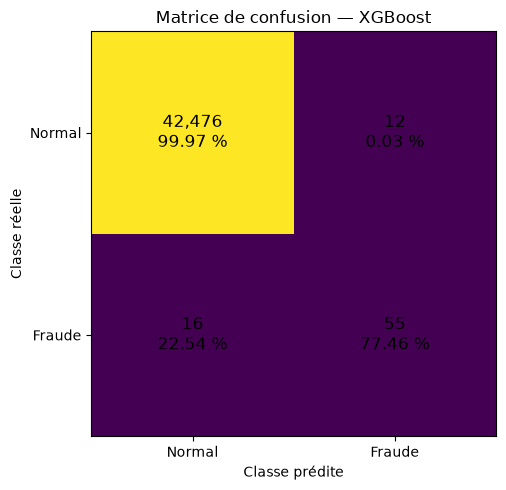

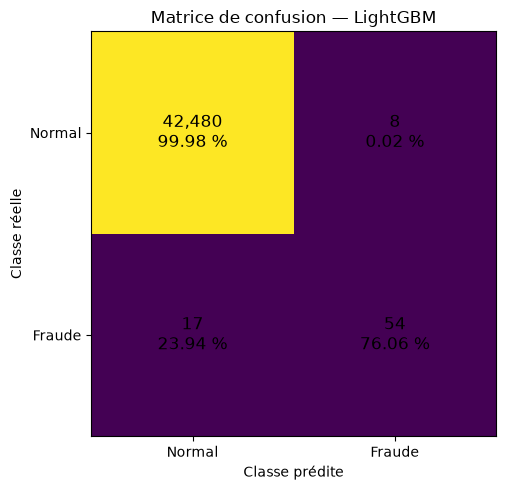

In [25]:
for model_name in model_file_names.keys():

    y_pred = test_predictions[
        f"{model_name}_pred"
    ]

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    # Pourcentage calculé par vraie classe
    cm_pct = (
        cm
        / cm.sum(axis=1, keepdims=True)
        * 100
    )

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    ax.imshow(cm)

    # Ajouter nombre + pourcentage
    for i in range(2):
        for j in range(2):

            ax.text(
                j,
                i,
                f"{cm[i, j]:,}\n{cm_pct[i, j]:.2f} %",
                ha="center",
                va="center",
                fontsize=12
            )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ["Normal", "Fraude"]
    )

    ax.set_yticks([0, 1])
    ax.set_yticklabels(
        ["Normal", "Fraude"]
    )

    ax.set_xlabel(
        "Classe prédite"
    )

    ax.set_ylabel(
        "Classe réelle"
    )

    ax.set_title(
        f"Matrice de confusion — {model_name}"
    )

    fig.tight_layout()

    filename = (
        model_file_names[model_name]
        + "_confusion_matrix.png"
    )

    fig.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

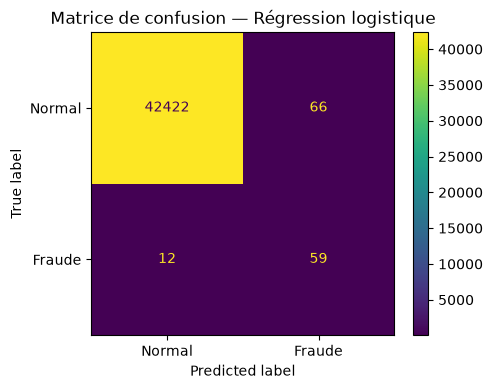

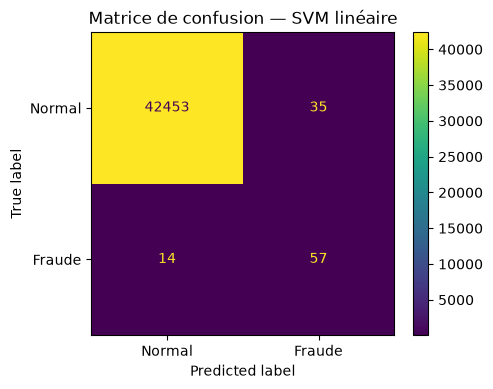

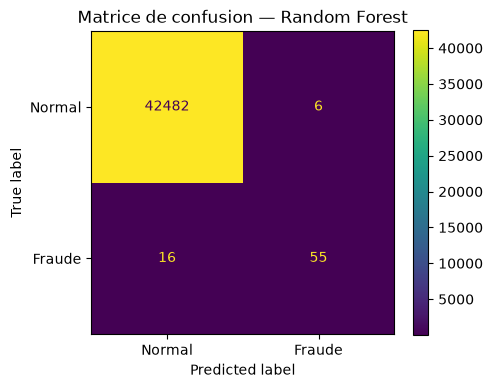

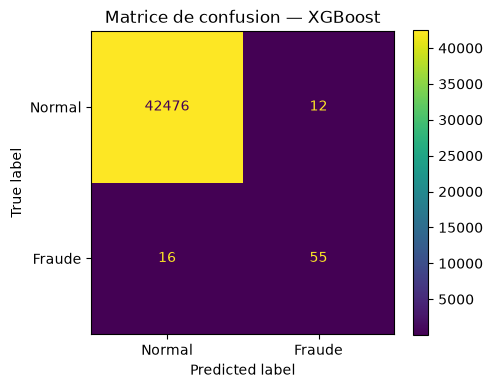

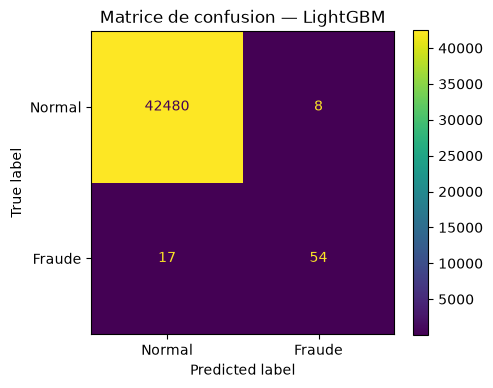

In [24]:
for model_name in model_file_names.keys():

    y_pred = test_predictions[
        f"{model_name}_pred"
    ]

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    fig, ax = plt.subplots(
        figsize=(5, 4)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Normal",
            "Fraude"
        ]
    )

    disp.plot(
        ax=ax,
        values_format="d"
    )

    ax.set_title(
        f"Matrice de confusion — {model_name}"
    )

    fig.tight_layout()

    filename = (
        model_file_names[
            model_name
        ]
        +
        "_confusion_matrix.png"
    )

    fig.savefig(
        FIGURES_DIR /
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [23]:
comparison_df.to_csv(
    METRICS_DIR /
    "baseline_vs_augmented_test.csv",
    index=False
)

In [22]:
display(
    comparison_df[
        [
            "Modèle",

            "Precision_Avant",
            "Precision_Après",
            "Delta_Precision",

            "Recall_Avant",
            "Recall_Après",
            "Delta_Recall",

            "F1_Avant",
            "F1_Après",
            "Delta_F1",

            "AP_Avant",
            "AP_Après",
            "Delta_AP"
        ]
    ].round(4)
)

,Modèle,Precision_Avant,Precision_Après,Delta_Precision,Recall_Avant,Recall_Après,Delta_Recall,F1_Avant,F1_Après,Delta_F1,AP_Avant,AP_Après,Delta_AP
0,Régression logistique,0.8372,0.4720,-0.3652,0.5070,0.8310,0.3239,0.6316,0.6020,-0.0295,0.6743,0.6928,0.0185
1,SVM linéaire,0.8723,0.6196,-0.2528,0.5775,0.8028,0.2254,0.6949,0.6994,0.0045,0.7177,0.7058,-0.0119
2,Random Forest,0.9322,0.9016,-0.0306,0.7746,0.7746,0.0000,0.8462,0.8333,-0.0128,0.7841,0.8284,0.0443
3,XGBoost,0.9286,0.8209,-0.1077,0.7324,0.7746,0.0423,0.8189,0.7971,-0.0218,0.8132,0.8004,-0.0128
4,LightGBM,0.3117,0.8710,0.5593,0.3380,0.7606,0.4225,0.3243,0.8120,0.4877,0.1065,0.7911,0.6846


In [21]:
metrics_to_compare = [
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "AP"
]

for metric in metrics_to_compare:

    comparison_df[
        f"Delta_{metric}"
    ] = (
        comparison_df[
            f"{metric}_Après"
        ]
        -
        comparison_df[
            f"{metric}_Avant"
        ]
    )

In [20]:
comparison_df = (
    baseline_test_df
    .merge(
        augmented_test_df,
        on="Modèle",
        suffixes=(
            "_Avant",
            "_Après"
        )
    )
)

## Étape 16 — Comparaison avant et après augmentation

Les performances des cinq classifieurs entraînés sur le Train
original déséquilibré sont maintenant comparées à celles obtenues
après augmentation par SMOTE avec un ratio Fraude/Normal de 0.10.

Cette comparaison est réalisée sur exactement le même jeu de
Test réel.

Les écarts permettent de mesurer l'effet propre de
l'augmentation sur chaque classifieur.

In [19]:
baseline_test_df.to_csv(
    METRICS_DIR /
    "baseline_test_recomputed_09.csv",
    index=False
)

In [18]:
baseline_test_df = pd.DataFrame(
    baseline_test_rows
)

display(
    baseline_test_df.round(4)
)

,Modèle,Temps_s,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,AP,TN,FP,FN,TP
0,Régression logistique,0.1877,0.9990,0.7534,0.8372,0.5070,0.6316,0.9319,0.6743,42481,7,35,36
1,SVM linéaire,0.5503,0.9992,0.7887,0.8723,0.5775,0.6949,0.9488,0.7177,42482,6,30,41
2,Random Forest,27.9607,0.9995,0.8873,0.9322,0.7746,0.8462,0.9192,0.7841,42484,4,16,55
3,XGBoost,1.4998,0.9995,0.8662,0.9286,0.7324,0.8189,0.9761,0.8132,42484,4,19,52
4,LightGBM,0.8380,0.9977,0.6684,0.3117,0.3380,0.3243,0.6683,0.1065,42435,53,47,24


In [17]:
baseline_test_rows = []

baseline_models = make_models()

for model_name, model in baseline_models.items():

    print(
        "Baseline →",
        model_name
    )

    start = time.perf_counter()

    model.fit(
        X_train,
        y_train
    )

    training_time = (
        time.perf_counter()
        -
        start
    )

    metrics, _, _ = (
        evaluate_classifier(
            model,
            X_test,
            y_test
        )
    )

    baseline_test_rows.append({

        "Modèle":
            model_name,

        "Temps_s":
            training_time,

        **metrics
    })

Baseline → Régression logistique
Baseline → SVM linéaire
Baseline → Random Forest
Baseline → XGBoost
Baseline → LightGBM


## Étape 15 — Recalcul de la baseline sur le même Test

Afin d'effectuer une comparaison strictement homogène,
les cinq classifieurs sont également réentraînés sur le Train
original déséquilibré avec les mêmes configurations.

Les performances sont mesurées sur exactement le même jeu
de Test réel.

Cette étape ne sert pas à sélectionner ou optimiser les modèles.
Elle permet uniquement de mesurer l'effet de l'augmentation.

In [16]:
augmented_test_df.to_csv(
    METRICS_DIR /
    "augmented_test_metrics.csv",
    index=False
)

test_predictions.to_parquet(
    METRICS_DIR /
    "augmented_test_predictions.parquet",
    index=False
)

print(
    "Résultats Test sauvegardés."
)

Résultats Test sauvegardés.


In [15]:
augmented_test_df = pd.DataFrame(
    augmented_test_rows
)

display(
    augmented_test_df.round(4)
)

,Modèle,Temps_s,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,AP,TN,FP,FN,TP
0,Régression logistique,1.4854,0.9982,0.9147,0.4720,0.8310,0.6020,0.9476,0.6928,42422,66,12,59
1,SVM linéaire,1.3114,0.9988,0.9010,0.6196,0.8028,0.6994,0.9564,0.7058,42453,35,14,57
2,Random Forest,26.7959,0.9995,0.8873,0.9016,0.7746,0.8333,0.9847,0.8284,42482,6,16,55
3,XGBoost,3.5141,0.9993,0.8872,0.8209,0.7746,0.7971,0.9748,0.8004,42476,12,16,55
4,LightGBM,1.1043,0.9994,0.8802,0.8710,0.7606,0.8120,0.9698,0.7911,42480,8,17,54


In [14]:
augmented_models[
    "XGBoost"
].save_model(
    MODELS_DIR /
    "xgboost.json"
)

print(
    "XGBoost sauvegardé en JSON."
)

XGBoost sauvegardé en JSON.


In [13]:
augmented_models = {}

augmented_test_rows = []

test_predictions = pd.DataFrame({
    "y_true":
        y_test
        .reset_index(drop=True)
})

model_file_names = {

    "Régression logistique":
        "logistic_regression",

    "SVM linéaire":
        "linear_svm",

    "Random Forest":
        "random_forest",

    "XGBoost":
        "xgboost",

    "LightGBM":
        "lightgbm"
}

models = make_models()

for model_name, model in models.items():

    print("\n")
    print("=" * 60)
    print(model_name)
    print("=" * 60)

    start = time.perf_counter()

    model.fit(
        X_train_aug,
        y_train_aug
    )

    training_time = (
        time.perf_counter()
        -
        start
    )

    metrics, y_pred, y_score = (
        evaluate_classifier(
            model,
            X_test,
            y_test
        )
    )

    augmented_test_rows.append({

        "Modèle":
            model_name,

        "Temps_s":
            training_time,

        **metrics
    })

    augmented_models[
        model_name
    ] = model

    test_predictions[
        f"{model_name}_pred"
    ] = y_pred

    test_predictions[
        f"{model_name}_score"
    ] = y_score

    filename = (
        MODELS_DIR /
        f"{model_file_names[model_name]}.joblib"
    )

    joblib.dump(
        model,
        filename
    )

    print(
        "F1 :",
        round(
            metrics["F1"],
            4
        )
    )

    print(
        "Recall :",
        round(
            metrics["Recall"],
            4
        )
    )

    print(
        "Precision :",
        round(
            metrics["Precision"],
            4
        )
    )

    print(
        "AP :",
        round(
            metrics["AP"],
            4
        )
    )



Régression logistique
F1 : 0.602
Recall : 0.831
Precision : 0.472
AP : 0.6928


SVM linéaire
F1 : 0.6994
Recall : 0.8028
Precision : 0.6196
AP : 0.7058


Random Forest
F1 : 0.8333
Recall : 0.7746
Precision : 0.9016
AP : 0.8284


XGBoost
F1 : 0.7971
Recall : 0.7746
Precision : 0.8209
AP : 0.8004


LightGBM
F1 : 0.812
Recall : 0.7606
Precision : 0.871
AP : 0.7911


In [12]:
def evaluate_classifier(
    model,
    X_eval,
    y_eval
):

    y_pred = model.predict(
        X_eval
    )

    y_score = get_model_scores(
        model,
        X_eval
    )

    tn, fp, fn, tp = (
        confusion_matrix(
            y_eval,
            y_pred
        )
        .ravel()
    )

    metrics = {

        "Accuracy":
            accuracy_score(
                y_eval,
                y_pred
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_eval,
                y_pred
            ),

        "Precision":
            precision_score(
                y_eval,
                y_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_eval,
                y_pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_eval,
                y_pred,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_eval,
                y_score
            ),

        "AP":
            average_precision_score(
                y_eval,
                y_score
            ),

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }

    return (
        metrics,
        y_pred,
        y_score
    )

In [11]:
def get_model_scores(
    model,
    X
):

    if hasattr(
        model,
        "predict_proba"
    ):

        return model.predict_proba(
            X
        )[:, 1]

    if hasattr(
        model,
        "decision_function"
    ):

        return model.decision_function(
            X
        )

    return model.predict(
        X
    )

In [10]:
def make_models():

    return {

        "Régression logistique":
            LogisticRegression(
                max_iter=2000,
                class_weight=None,
                random_state=42
            ),

        "SVM linéaire":
            LinearSVC(
                C=1.0,
                class_weight=None,
                max_iter=5000,
                random_state=42
            ),

        "Random Forest":
            RandomForestClassifier(
                n_estimators=200,
                class_weight=None,
                random_state=42,
                n_jobs=-1
            ),

        "XGBoost":
            XGBClassifier(
                n_estimators=200,
                learning_rate=0.1,
                max_depth=6,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            ),

        "LightGBM":
            LGBMClassifier(
                n_estimators=200,
                learning_rate=0.1,
                class_weight=None,
                random_state=42,
                n_jobs=-1,
                verbosity=-1
            )
    }

In [9]:
print(
    "NaN Train augmenté :",
    int(
        X_train_aug
        .isna()
        .sum()
        .sum()
    )
)

print(
    "Inf Train augmenté :",
    int(
        np.isinf(
            X_train_aug.to_numpy()
        ).sum()
    )
)

print(
    "Nombre de lignes :",
    len(X_train_aug)
)

print(
    "Nombre de labels :",
    len(y_train_aug)
)

print(
    "Ratio réel obtenu :",
    round(
        (
            y_train_aug == 1
        ).sum()
        /
        (
            y_train_aug == 0
        ).sum(),
        4
    )
)

NaN Train augmenté : 0
Inf Train augmenté : 0
Nombre de lignes : 218105
Nombre de labels : 218105
Ratio réel obtenu : 0.1


In [8]:
X_train_aug, y_train_aug, n_added = (
    build_augmented_train(
        X_train=X_train,
        y_train=y_train,
        synthetic_data=smote_synthetic,
        target_ratio=BEST_RATIO,
        random_state=SEED
    )
)

print(
    "Train augmenté :",
    X_train_aug.shape
)

print()

print(
    y_train_aug.value_counts()
)

print()

print(
    "Fraudes synthétiques ajoutées :",
    n_added
)

Train augmenté : (218105, 30)

Class
0    198277
1     19828
Name: count, dtype: int64

Fraudes synthétiques ajoutées : 19497


In [7]:
def build_augmented_train(
    X_train,
    y_train,
    synthetic_data,
    target_ratio,
    random_state=42
):

    n_normal = int(
        (y_train == 0).sum()
    )

    n_real_fraud = int(
        (y_train == 1).sum()
    )

    target_fraud = int(
        round(
            target_ratio
            *
            n_normal
        )
    )

    n_synthetic_needed = (
        target_fraud
        -
        n_real_fraud
    )

    if n_synthetic_needed < 0:

        raise ValueError(
            "Le ratio demandé est inférieur "
            "au ratio déjà présent."
        )

    if n_synthetic_needed > len(
        synthetic_data
    ):

        raise ValueError(
            "Pas assez de données synthétiques."
        )

    synthetic_sample = (
        synthetic_data
        .sample(
            n=n_synthetic_needed,
            random_state=random_state
        )
        .reset_index(drop=True)
    )

    y_synthetic = pd.Series(
        np.ones(
            n_synthetic_needed,
            dtype=np.int8
        ),
        name=y_train.name
    )

    X_augmented = pd.concat(
        [
            X_train.reset_index(drop=True),
            synthetic_sample
        ],
        ignore_index=True
    )

    y_augmented = pd.concat(
        [
            y_train.reset_index(drop=True),
            y_synthetic
        ],
        ignore_index=True
    )

    return (
        X_augmented,
        y_augmented,
        n_synthetic_needed
    )

In [6]:
selected_synthetic_path = (
    SYNTHETIC_DIR /
    "smote_fraud_synthetic.parquet"
)

smote_synthetic = pd.read_parquet(
    selected_synthetic_path
)

if "Class" in smote_synthetic.columns:

    print(
        "Colonne Class détectée → suppression"
    )

    smote_synthetic = (
        smote_synthetic
        .drop(
            columns=["Class"]
        )
    )

if list(smote_synthetic.columns) != list(
    X_train.columns
):
    raise ValueError(
        "Les colonnes synthétiques ne correspondent pas au Train."
    )

print(
    "Fraudes synthétiques disponibles :",
    smote_synthetic.shape
)

Colonne Class détectée → suppression
Fraudes synthétiques disponibles : (197946, 30)


In [5]:
X_train = pd.read_parquet(
    PROCESSED_DIR /
    "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR /
    "y_train.parquet"
).squeeze()

X_test = pd.read_parquet(
    PROCESSED_DIR /
    "X_test.parquet"
)

y_test = pd.read_parquet(
    PROCESSED_DIR /
    "y_test.parquet"
).squeeze()

print(
    "Train :",
    X_train.shape
)

print(
    y_train.value_counts()
)

print()

print(
    "Test :",
    X_test.shape
)

print(
    y_test.value_counts()
)

Train : (198608, 30)
Class
0    198277
1       331
Name: count, dtype: int64

Test : (42559, 30)
Class
0    42488
1       71
Name: count, dtype: int64


In [4]:
selection_path = (
    METRICS_DIR /
    "synthetic_selection.json"
)

if not selection_path.exists():
    raise FileNotFoundError(
        "Le fichier synthetic_selection.json est introuvable."
    )

with open(
    selection_path,
    "r",
    encoding="utf-8"
) as f:

    selection = json.load(f)

BEST_METHOD = selection[
    "augmentation_method"
]

BEST_RATIO = float(
    selection[
        "target_fraud_normal_ratio"
    ]
)

print(
    "Méthode sélectionnée :",
    BEST_METHOD
)

print(
    "Ratio sélectionné :",
    BEST_RATIO
)

print(
    "Test utilisé pendant la sélection :",
    selection[
        "test_used_for_selection"
    ]
)

Méthode sélectionnée : SMOTE
Ratio sélectionné : 0.1
Test utilisé pendant la sélection : False


In [3]:
BEST_METHOD = "SMOTE"
BEST_RATIO = 0.10

In [2]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = (
    PROJECT_ROOT /
    "data" /
    "processed"
)

SYNTHETIC_DIR = (
    PROJECT_ROOT /
    "results" /
    "synthetic"
)

METRICS_DIR = (
    PROJECT_ROOT /
    "results" /
    "metrics"
)

FIGURES_DIR = (
    PROJECT_ROOT /
    "results" /
    "figures"
)

MODELS_DIR = (
    PROJECT_ROOT /
    "models" /
    "augmented"
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Projet :", PROJECT_ROOT)

Projet : c:\Users\MSI\Desktop\fraud_detection_memoire


In [1]:
from pathlib import Path
import json
import time
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")

SEED = 42

print("Imports OK")

Imports OK


# 09 — Entraînement et évaluation des modèles sur le Train augmenté

## Objectif

Le notebook précédent a permis de sélectionner la stratégie
d'augmentation SMOTE avec un ratio Fraude/Normal de 0.10,
exclusivement à partir du jeu de Validation réel.

Ce notebook applique désormais cette stratégie au jeu
d'entraînement afin de réentraîner les cinq classifieurs étudiés :

- Régression logistique
- SVM linéaire
- Random Forest
- XGBoost
- LightGBM

Les modèles sont ensuite évalués sur le jeu de Test réel,
qui n'intervient dans aucun choix de méthode, ratio,
hyperparamètre ou seuil.

Les performances obtenues après augmentation sont comparées
aux performances de la baseline entraînée sur le Train
déséquilibré.

Aucun modèle final n'est sélectionné dans ce notebook.

La robustesse des cinq modèles sera étudiée ultérieurement
à l'aide de l'attaque ZOO et de l'Adversarial Training.